# BdSLW60 - Confusion matrices on the official test signers

In [1]:
# ---- Cell 1: find every saved prediction ----
import re, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
INPUT_ROOT = Path('/kaggle/input'); OUT = Path('/kaggle/working'); OUT.mkdir(exist_ok=True)
TEST_SIGNERS = (4, 8)
N_BOOT = 10000
rng = np.random.default_rng(0)

metas = sorted(INPUT_ROOT.rglob('meta.csv')); ys = sorted(INPUT_ROOT.rglob('y.npy'))
assert metas and ys, 'attach at least one notebook output that contains bdslw60_w2/meta.csv and y.npy'
meta = pd.read_csv(metas[0]); y = np.load(ys[0])
for p in ys[1:]:                       # every notebook must have built the same arrays
    y2 = np.load(p)
    if len(y2) != len(y) or (y2 != y).any():
        warnings.warn('labels differ in %s: predictions are checked against their own labels below' % p)
TEST = np.flatnonzero(meta.user.isin(TEST_SIGNERS).values)            # order of p1['test'] and of logits_test_*.npy
TEST_SORTED = np.concatenate([np.sort(np.flatnonzero(meta.user.values == u)) for u in TEST_SIGNERS])  # order of tta_probs
pos = {v: k for k, v in enumerate(TEST)}
signer = meta.user.values[TEST]
yt = y[TEST]
assert len(TEST) == 1276, len(TEST)
print('test clips: %d (U4 %d, U8 %d)' % (len(TEST), (signer == 4).sum(), (signer == 8).sum()))

PRED = {}    # key -> {seed: predicted class per clip, in TEST order}
PROB = {}    # key -> {seed: (1276, 60) probabilities, in TEST order} where available
def add(key, seed, pred=None, prob=None, src=''):
    if prob is not None:
        prob = np.asarray(prob, np.float64); pred = prob.argmax(1)
        PROB.setdefault(key, {})[seed] = prob
    if seed in PRED.get(key, {}) and (PRED[key][seed] != pred).any():
        warnings.warn('%s seed %d found twice with different predictions; keeping the first (%s ignored)' % (key, seed, src)); return
    PRED.setdefault(key, {})[seed] = pred

# 1) predtest_<key>_seed<s>.csv (idx, pred, true)
for p in sorted(INPUT_ROOT.rglob('predtest_*_seed*.csv')):
    m = re.match(r'predtest_(.+)_seed(\d+)\.csv$', p.name)
    if not m or '_LOSO_' in m[1]:
        continue
    d = pd.read_csv(p)
    if len(d) != len(TEST) or set(d.idx) != set(TEST):
        continue
    if (d.true.values != y[d.idx.values]).any():
        warnings.warn('labels in %s do not match y.npy; skipped' % p); continue
    pred = np.empty(len(TEST), int); pred[[pos[i] for i in d.idx]] = d.pred.values
    add(m[1], int(m[2]), pred=pred, src=p)

# 2) logits_test_<key>_seed<s>.npy (multi-stream notebook, TEST order)
for p in sorted(INPUT_ROOT.rglob('logits_test_*_seed*.npy')):
    m = re.match(r'logits_test_(.+)_seed(\d+)\.npy$', p.name)
    L = np.load(p)
    if L.shape != (len(TEST), 60):
        continue
    P = np.exp(L - L.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
    add('MS_' + m[1], int(m[2]), prob=P, src=p)

# 3) tta_probs/P1_<stream>_seed<s>_<cfg>_<mode>.pt (compact ST-GCN streams, TEST_SORTED order)
try:
    import torch
except ImportError:
    torch = None
reorder = np.array([pos[v] for v in TEST_SORTED])
for p in sorted(INPUT_ROOT.rglob('P1_*_seed*_*.pt')):
    m = re.match(r'P1_(joint_motion|bone_motion|joint|bone)_seed(\d+)_(.+)_(inductive|transductive)\.pt$', p.name)
    if not m or torch is None:
        continue
    P = torch.load(p, map_location='cpu').numpy()
    Q = np.empty_like(P); Q[reorder] = P
    add('C_%s_%s_%s' % (m[1], m[3], m[4]), int(m[2]), prob=Q, src=p)

# 4) four-stream ensembles: equal-weight average of the stream probabilities, per seed
STREAMS = ('joint', 'bone', 'joint_motion', 'bone_motion')
cfgs = sorted({k.split('_', 2)[2] for k in PROB if k.startswith('C_joint_') and not k.startswith('C_joint_motion')})
for cfg in cfgs:
    ks = ['C_%s_%s' % (s, cfg) for s in STREAMS]
    if all(k in PROB for k in ks):
        for seed in set.intersection(*[set(PROB[k]) for k in ks]):
            add('ENS4_compact_' + cfg, seed, prob=sum(PROB[k][seed] for k in ks) / 4)
ks = ['MS_S0_slgcn'] + ['MS_S0_slgcn_' + s for s in STREAMS[1:]]
if all(k in PROB for k in ks):
    for seed in set.intersection(*[set(PROB[k]) for k in ks]):
        add('ENS4_slgcn', seed, prob=sum(PROB[k][seed] for k in ks) / 4)

print('\n%d prediction sets found:' % len(PRED))
for k in sorted(PRED):
    accs = [100 * (PRED[k][s] == yt).mean() for s in sorted(PRED[k])]
    print('  %-55s seeds %-9s top-1 %s' % (k, sorted(PRED[k]), ' '.join('%.2f' % a for a in accs)))

/tmp/ipykernel_16/89426332.py:17: UserWarning: labels differ in /kaggle/input/notebooks/rishta19/bdslw60-week-1/bdslw60_cache/y.npy: predictions are checked against their own labels below
  warnings.warn('labels differ in %s: predictions are checked against their own labels below' % p)
/tmp/ipykernel_16/89426332.py:17: UserWarning: labels differ in /kaggle/input/notebooks/rishta19/bdslw60-week-1-v2/bdslw60_cache/y.npy: predictions are checked against their own labels below
  warnings.warn('labels differ in %s: predictions are checked against their own labels below' % p)


test clips: 1276 (U4 637, U8 639)


/tmp/ipykernel_16/89426332.py:33: UserWarning: S0_slgcn seed 0 found twice with different predictions; keeping the first (/kaggle/input/notebooks/rishta123/bdslw60-multi-stream-ensemble/bdslw60_w2/predtest_S0_slgcn_seed0.csv ignored)
  warnings.warn('%s seed %d found twice with different predictions; keeping the first (%s ignored)' % (key, seed, src)); return
/tmp/ipykernel_16/89426332.py:33: UserWarning: S0_slgcn seed 1 found twice with different predictions; keeping the first (/kaggle/input/notebooks/rishta123/bdslw60-multi-stream-ensemble/bdslw60_w2/predtest_S0_slgcn_seed1.csv ignored)
  warnings.warn('%s seed %d found twice with different predictions; keeping the first (%s ignored)' % (key, seed, src)); return
/tmp/ipykernel_16/89426332.py:33: UserWarning: S0_slgcn seed 2 found twice with different predictions; keeping the first (/kaggle/input/notebooks/rishta123/bdslw60-multi-stream-ensemble/bdslw60_w2/predtest_S0_slgcn_seed2.csv ignored)
  warnings.warn('%s seed %d found twice wi


57 prediction sets found:
  BiLSTM_P1_adamw                                         seeds [0, 1, 2] top-1 83.46 82.99 84.01
  BiLSTM_P1_sgd                                           seeds [0, 1, 2] top-1 87.23 87.30 86.05
  BiLSTM_base_P1                                          seeds [0, 1, 2] top-1 76.72 81.58 80.88
  BiLSTM_base_P1_adamw                                    seeds [0, 1, 2] top-1 84.48 86.13 86.83
  BiLSTM_base_P1_sgd                                      seeds [0, 1, 2] top-1 87.77 89.11 88.24
  C_bone_bn_a1.0_inductive                                seeds [0, 1, 2] top-1 90.20 88.95 90.13
  C_bone_motion_bn_a1.0_inductive                         seeds [0, 1, 2] top-1 87.07 88.01 88.24
  C_bone_motion_none_inductive                            seeds [0, 1, 2] top-1 86.76 88.56 86.60
  C_bone_motion_self_a0.5_nobal_e30_inductive             seeds [0, 1, 2] top-1 89.81 90.52 88.95
  C_bone_motion_self_a0.5_nobal_e30_transductive          seeds [0, 1, 2] top-1 90.52 91.14

In [2]:
# ---- Cell 2: settings ----
MODEL_KEY = 'ENS4_compact_self_a0.5_nobal_e30_inductive'    # final system; any key listed by cell 1 works
SINGLE_KEY = 'STGCN_compact'                                # single model, for comparison
WORD_IDS = (list(range(1, 13)) + [19, 20] + list(range(37, 51)) + list(range(91, 101))
            + [111, 112] + list(range(211, 221)) + list(range(351, 361)))     # class index -> BdSLW60 word ID
GLOSS = {}            # optional, e.g. {6: 'Gloss of W6'}; word IDs are used where a gloss is missing
N_ZOOM_PAIRS = 10     # the zoom shows every word in the 10 most frequent confusions
def name(c):
    w = WORD_IDS[c]
    return GLOSS.get(w, 'W%d' % w)
assert MODEL_KEY in PRED, 'not found: %s. Available: %s' % (MODEL_KEY, sorted(PRED))

In [3]:
# ---- Cell 3: counts, most frequent confusions, per-word recall ----
def counts(key):
    Cm = np.zeros((60, 60), int)
    for s in PRED[key]:
        np.add.at(Cm, (yt, PRED[key][s]), 1)
    return Cm

def report(key, top=15):
    Cm = counts(key); n_seeds = len(PRED[key])
    off = Cm.copy(); np.fill_diagonal(off, 0)
    order = np.dstack(np.unravel_index(np.argsort(-off, axis=None), off.shape))[0][:top]
    print('=== %s: %d seeds, top-1 %.2f%% ===' % (key, n_seeds, 100 * np.trace(Cm) / Cm.sum()))
    print('most frequent confusions (true -> predicted, summed over seeds):')
    rows = [dict(true=name(i), predicted=name(j), errors=off[i, j], share_of_true_word=off[i, j] / Cm[i].sum())
            for i, j in order if off[i, j] > 0]
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    recv = np.diag(Cm) / Cm.sum(1)
    worst = np.argsort(recv)[:10]
    print('lowest recall:', ', '.join('%s %.0f%%' % (name(c), 100 * recv[c]) for c in worst))
    recv_in = off.sum(0)
    print('words that absorb the most errors:', ', '.join('%s (%d)' % (name(c), recv_in[c]) for c in np.argsort(-recv_in)[:5]))
    return Cm, off, order

Cm, off, order = report(MODEL_KEY)
pd.DataFrame(Cm, index=[name(c) for c in range(60)], columns=[name(c) for c in range(60)]).to_csv(OUT / 'confusion_counts.csv')
if SINGLE_KEY in PRED:
    print()
    report(SINGLE_KEY)

=== ENS4_compact_self_a0.5_nobal_e30_inductive: 3 seeds, top-1 93.60% ===
most frequent confusions (true -> predicted, summed over seeds):
true predicted  errors  share_of_true_word
  W9        W6      28               0.424
  W1        W6      23               0.365
 W48      W354      19               0.288
W356       W19      16               0.242
W100       W99      15               0.227
 W92        W8      13               0.181
W356      W211      12               0.182
 W43      W356      12               0.182
 W48       W98       9               0.136
 W92       W37       7               0.097
W216      W359       6               0.083
 W20        W6       6               0.100
 W42       W37       5               0.076
  W9       W20       5               0.076
 W48       W43       4               0.061
lowest recall: W9 50%, W48 52%, W356 55%, W1 63%, W92 67%, W216 69%, W43 74%, W20 77%, W100 77%, W42 82%
words that absorb the most errors: W6 (60), W354 (19), W19 (16), W99

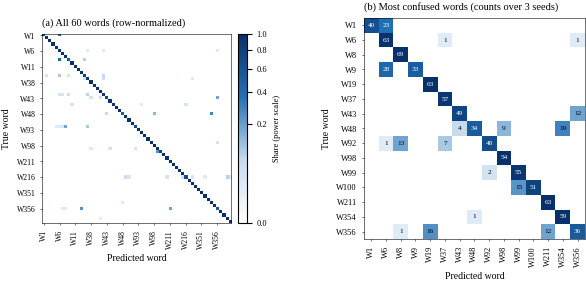

saved fig_confusion.pdf / .png and confusion_counts.csv


In [4]:
# ---- Cell 4: figure (vector PDF, two columns wide) ----
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'Times New Roman', 'DejaVu Serif'],
                     'font.size': 7, 'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02})
cmap = LinearSegmentedColormap.from_list('b', ['#FFFFFF', '#C6DBEF', '#2171B5', '#08306B'])
R = Cm / Cm.sum(1, keepdims=True)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 3.35), gridspec_kw=dict(width_ratios=[1, 1.08], wspace=0.55))
im = a1.imshow(R, cmap=cmap, norm=PowerNorm(0.4, vmin=0, vmax=1), interpolation='nearest')   # power scale makes small error rates visible
ticks = list(range(0, 60, 5))
a1.set_xticks(ticks); a1.set_xticklabels([name(c) for c in ticks], rotation=90, fontsize=5.5)
a1.set_yticks(ticks); a1.set_yticklabels([name(c) for c in ticks], fontsize=5.5)
a1.set_xlabel('Predicted word'); a1.set_ylabel('True word')
a1.set_title('(a) All 60 words (row-normalized)', loc='left', fontsize=7.5)
cb = fig.colorbar(im, ax=a1, fraction=0.046, pad=0.03); cb.ax.tick_params(labelsize=6); cb.set_label('Share (power scale)', fontsize=6)

# zoom: words in the most frequent confusions, kept in class order
words = []
for i, j in order[:N_ZOOM_PAIRS]:
    for c in (i, j):
        if c not in words and off[i, j] > 0:
            words.append(c)
words = sorted(words)
Z = Cm[np.ix_(words, words)]
Zr = Z / Cm[words].sum(1, keepdims=True)
a2.imshow(Zr, cmap=cmap, norm=PowerNorm(0.4, vmin=0, vmax=1), interpolation='nearest')
for r in range(len(words)):
    for c in range(len(words)):
        if Z[r, c]:
            a2.text(c, r, str(Z[r, c]), ha='center', va='center', fontsize=5.2,
                    color='white' if Zr[r, c] > 0.35 else 'black')
a2.set_xticks(range(len(words))); a2.set_xticklabels([name(c) for c in words], rotation=90, fontsize=6)
a2.set_yticks(range(len(words))); a2.set_yticklabels([name(c) for c in words], fontsize=6)
a2.set_xlabel('Predicted word'); a2.set_ylabel('True word')
a2.set_title('(b) Most confused words (counts over %d seeds)' % len(PRED[MODEL_KEY]), loc='left', fontsize=7.5)
for a in (a1, a2):
    a.tick_params(length=1.5, width=0.4)
    for sp in a.spines.values():
        sp.set_linewidth(0.4)
fig.savefig(OUT / 'fig_confusion.pdf'); fig.savefig(OUT / 'fig_confusion.png', dpi=220)
plt.show()
print('saved fig_confusion.pdf / .png and confusion_counts.csv')